In [5]:
from pathlib import Path

DATA = Path("../data")

print("train/good:", len(list((DATA / "train" / "good").glob("*.png"))))
for folder in sorted((DATA / "test").iterdir()):
    print(f"test/{folder.name}:", len(list(folder.glob("*.png"))))

train/good: 209
test/broken_large: 20
test/broken_small: 22
test/contamination: 21
test/good: 20


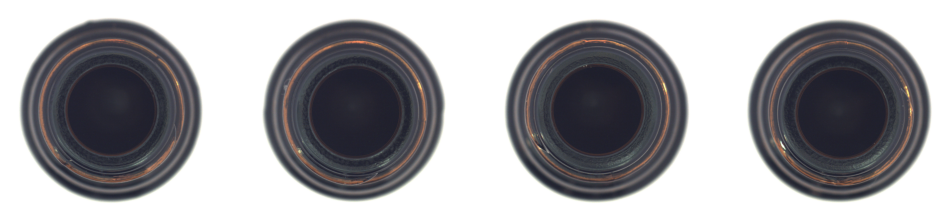

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

files = sorted((DATA / "train" / "good").glob("*.png"))[:4]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, f in zip(axes, files):
    ax.imshow(Image.open(f))
    ax.axes("off")
plt.show()

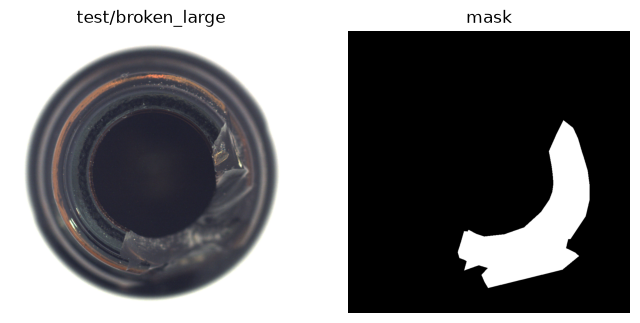

In [ ]:
types = [c.name for c in (DATA / "test").iterdir() if c.name != "good"][0]
image = sorted((DATA / "test" / types).glob("*.png"))[0]
mask = DATA / "ground_truth" / types / f"{image.stem}_mask.png"

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(image));   axes[0].set_title(f"test/{types}")
axes[1].imshow(Image.open(mask), cmap="gray"); axes[1].set_title("mask")
for e in axes: e.axes("off")
plt.show()

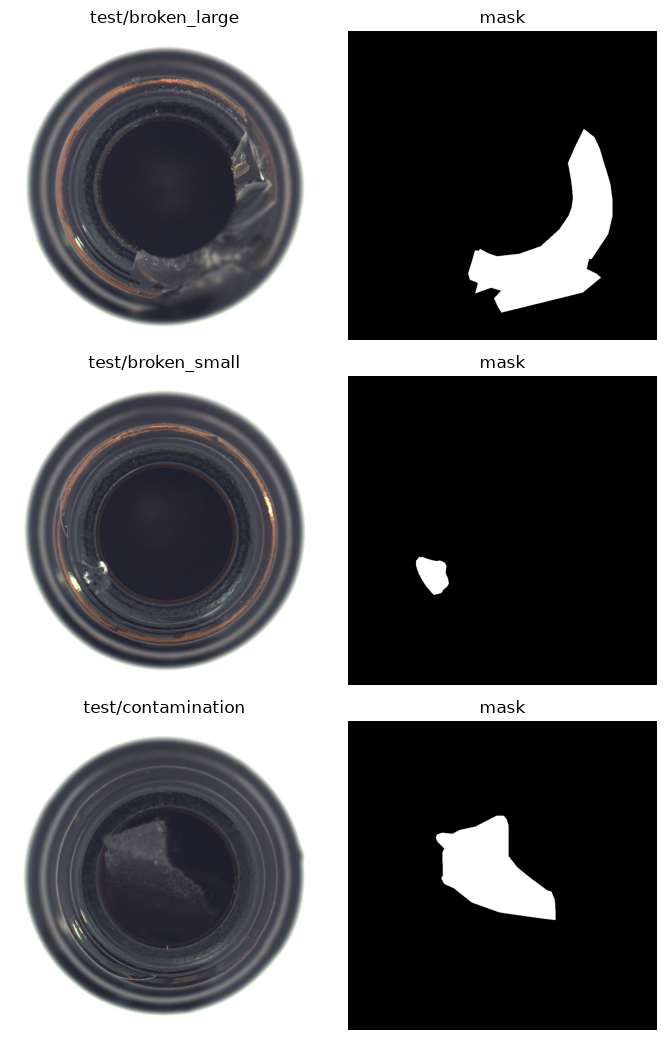

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

defect_types = sorted(
    folder.name for folder in (DATA / "test").iterdir() if folder.name != "good"
)

fig, axes = plt.subplots(len(defect_types), 2, figsize=(7, 3.5 * len(defect_types)))

for row, defect in zip(axes, defect_types):
    image_path = sorted((DATA / "test" / defect).glob("*.png"))[0]
    mask_path = DATA / "ground_truth" / defect / f"{image_path.stem}_mask.png"

    row[0].imshow(Image.open(image_path))
    row[0].set_title(f"test/{defect}")
    row[1].imshow(Image.open(mask_path), cmap="gray")
    row[1].set_title("mask")

    for ax in row:
        ax.axes("off")

plt.tight_layout()
plt.show()